In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import sys
import tensorflow as tf
import keras
import numpy as np
import sklearn
import matplotlib
import PIL
import pandas as pd

print("Python:       ", sys.version.split()[0])
print("TensorFlow:   ", tf.__version__)
print("Keras:        ", keras.__version__)
print("NumPy:        ", np.__version__)
print("Scikit-learn: ", sklearn.__version__)
print("Matplotlib:   ", matplotlib.__version__)
print("Pillow:       ", PIL.__version__)
print("Pandas:       ", pd.__version__)

Python:        3.13.15
TensorFlow:    2.21.0
Keras:         3.13.2
NumPy:         2.1.3
Scikit-learn:  1.6.1
Matplotlib:    3.10.0
Pillow:        11.3.0
Pandas:        2.2.3


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

TCC = Path("/content/drive/MyDrive/TCC")
DATASET = TCC / "DATASET" / "Dividido_224"

print("TCC encontrada:", TCC.exists())
print("Dataset encontrado:", DATASET.exists())

if DATASET.exists():
    print("\nPastas dentro de Dividido_224:")
    for item in DATASET.iterdir():
        print(repr(item.name))

TCC encontrada: True
Dataset encontrado: True

Pastas dentro de Dividido_224:
'Treino'
'Validação'
'Teste'


In [ ]:
import shutil
from pathlib import Path

DATASET_LOCAL = Path("/content/DATASET/Dividido_224")

if DATASET_LOCAL.exists():
    print("Dataset local já existe:", DATASET_LOCAL)
else:
    print("Copiando dataset para o armazenamento local do Colab...")

    shutil.copytree(
        DATASET,
        DATASET_LOCAL
    )

    print("Cópia concluída.")

print("Dataset local:", DATASET_LOCAL)
print("Existe:", DATASET_LOCAL.exists())

Copiando dataset para o armazenamento local do Colab...
Cópia concluída.
Dataset local: /content/DATASET/Dividido_224
Existe: True


In [ ]:
total_geral = 0

for divisao in sorted(DATASET_LOCAL.iterdir()):
    if divisao.is_dir():
        print(f"\n{divisao.name}:")

        total_divisao = 0

        for classe in sorted(divisao.iterdir()):
            if classe.is_dir():
                imagens = [
                    arq for arq in classe.iterdir()
                    if arq.suffix.lower() in {".jpg", ".jpeg", ".png"}
                ]

                quantidade = len(imagens)
                total_divisao += quantidade
                total_geral += quantidade

                print(f"  {classe.name}: {quantidade}")

        print(f"  Total da divisão: {total_divisao}")

print(f"\nTotal geral: {total_geral}")


Teste:
  Ferrugem-asiática: 240
  Mancha-alvo: 167
  Mancha-olho-de-rã: 242
  Mancha-púrpura: 203
  Saudável: 227
  Total da divisão: 1079

Treino:
  Ferrugem-asiática: 1123
  Mancha-alvo: 782
  Mancha-olho-de-rã: 1130
  Mancha-púrpura: 948
  Saudável: 1060
  Total da divisão: 5043

Validação:
  Ferrugem-asiática: 241
  Mancha-alvo: 168
  Mancha-olho-de-rã: 242
  Mancha-púrpura: 203
  Saudável: 227
  Total da divisão: 1081

Total geral: 7203


In [ ]:
import random
import numpy as np
import tensorflow as tf

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 5

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Localiza automaticamente as divisões na cópia local
pastas_local = {
    item.name: item
    for item in DATASET_LOCAL.iterdir()
    if item.is_dir()
}

for nome, caminho in pastas_local.items():
    if nome == "Treino":
        TRAIN_DIR_LOCAL = caminho
    elif nome == "Teste":
        TEST_DIR_LOCAL = caminho
    elif nome.startswith("Valid"):
        VAL_DIR_LOCAL = caminho

print("Treino:", TRAIN_DIR_LOCAL)
print("Validação:", VAL_DIR_LOCAL)
print("Teste:", TEST_DIR_LOCAL)

print("\nTamanho das imagens:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Número de classes:", NUM_CLASSES)
print("Seed:", SEED)

Treino: /content/DATASET/Dividido_224/Treino
Validação: /content/DATASET/Dividido_224/Validação
Teste: /content/DATASET/Dividido_224/Teste

Tamanho das imagens: (224, 224)
Batch size: 32
Número de classes: 5
Seed: 42


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR_LOCAL,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR_LOCAL,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR_LOCAL,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names

print("\nClasses reconhecidas:")
print(CLASS_NAMES)

Found 5043 files belonging to 5 classes.
Found 1081 files belonging to 5 classes.
Found 1079 files belonging to 5 classes.

Classes reconhecidas:
['Ferrugem-asiática', 'Mancha-alvo', 'Mancha-olho-de-rã', 'Mancha-púrpura', 'Saudável']


In [ ]:
preprocess_input = tf.keras.applications.resnet50.preprocess_input

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Pré-processamento da ResNet50 aplicado com sucesso.")
print("Classes:", CLASS_NAMES)

Pré-processamento da ResNet50 aplicado com sucesso.
Classes: ['Ferrugem-asiática', 'Mancha-alvo', 'Mancha-olho-de-rã', 'Mancha-púrpura', 'Saudável']


In [ ]:
base_model = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(x)

model = tf.keras.Model(inputs, outputs)

print("ResNet50 criada com sucesso.")
print("Base congelada:", not base_model.trainable)
print("Número de classes:", NUM_CLASSES)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50 criada com sucesso.
Base congelada: True
Número de classes: 5


In [ ]:
model.summary()

trainable_params = np.sum(
    [np.prod(v.shape) for v in model.trainable_weights]
)

non_trainable_params = np.sum(
    [np.prod(v.shape) for v in model.non_trainable_weights]
)

print("\nParâmetros treináveis:", trainable_params)
print("Parâmetros não treináveis:", non_trainable_params)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)


Parâmetros treináveis: 10245
Parâmetros não treináveis: 23587712


In [ ]:
print("Base ResNet50 treinável:", base_model.trainable)

print("\nPesos treináveis do modelo:")
for peso in model.trainable_weights:
    print(peso.name, peso.shape)

print("\nTotal de parâmetros treináveis:")
print(
    sum(
        tf.keras.backend.count_params(p)
        for p in model.trainable_weights
    )
)

Base ResNet50 treinável: False

Pesos treináveis do modelo:
kernel (2048, 5)
bias (5,)

Total de parâmetros treináveis:
10245


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 compilada com sucesso.")

ResNet50 compilada com sucesso.


In [ ]:
from pathlib import Path

RESULTADOS = TCC / "RESULTADOS" / "ResNet50"
RESULTADOS.mkdir(parents=True, exist_ok=True)

CHECKPOINT = RESULTADOS / "melhor_modelo_fase1.keras"

callbacks_fase1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks configurados com sucesso.")
print("Resultados serão salvos em:", RESULTADOS)

Callbacks configurados com sucesso.
Resultados serão salvos em: /content/drive/MyDrive/TCC/RESULTADOS/ResNet50


In [ ]:
EPOCHS_FASE1 = 16

history_fase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FASE1,
    callbacks=callbacks_fase1,
    verbose=1
)

Epoch 1/16
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5518 - loss: 1.1766
Epoch 1: val_loss improved from None to 0.40346, saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_fase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_fase1.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 52s 227ms/step - accuracy: 0.6996 - loss: 0.7909 - val_accuracy: 0.8668 - val_loss: 0.4035 - learning_rate: 0.0010
Epoch 2/16
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.8477 - loss: 0.4156
Epoch 2: val_loss improved from 0.40346 to 0.31364, saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_fase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_fase1.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 22s 137ms/step - accuracy: 0.8588 - loss: 0.3996 - val_accuracy: 0.8982 - val_loss: 0.3136 - learning_rate: 0.0010
Epoch 3/16
158/158 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
for i, layer in enumerate(base_model.layers[-50:]):
    indice_real = len(base_model.layers) - 50 + i
    print(indice_real, layer.name, type(layer).__name__)

125 conv4_block5_1_relu Activation
126 conv4_block5_2_conv Conv2D
127 conv4_block5_2_bn BatchNormalization
128 conv4_block5_2_relu Activation
129 conv4_block5_3_conv Conv2D
130 conv4_block5_3_bn BatchNormalization
131 conv4_block5_add Add
132 conv4_block5_out Activation
133 conv4_block6_1_conv Conv2D
134 conv4_block6_1_bn BatchNormalization
135 conv4_block6_1_relu Activation
136 conv4_block6_2_conv Conv2D
137 conv4_block6_2_bn BatchNormalization
138 conv4_block6_2_relu Activation
139 conv4_block6_3_conv Conv2D
140 conv4_block6_3_bn BatchNormalization
141 conv4_block6_add Add
142 conv4_block6_out Activation
143 conv5_block1_1_conv Conv2D
144 conv5_block1_1_bn BatchNormalization
145 conv5_block1_1_relu Activation
146 conv5_block1_2_conv Conv2D
147 conv5_block1_2_bn BatchNormalization
148 conv5_block1_2_relu Activation
149 conv5_block1_0_conv Conv2D
150 conv5_block1_3_conv Conv2D
151 conv5_block1_0_bn BatchNormalization
152 conv5_block1_3_bn BatchNormalization
153 conv5_block1_add Add
154

In [ ]:
base_model.trainable = True

# Primeiro congela novamente todas as camadas
for layer in base_model.layers:
    layer.trainable = False

# Libera apenas o estágio conv5
for layer in base_model.layers:
    if layer.name.startswith("conv5_"):
        if not isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = True

print("Fine-tuning da ResNet50 configurado.")

print("\nCamadas treináveis da base:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name, type(layer).__name__)

Fine-tuning da ResNet50 configurado.

Camadas treináveis da base:
conv5_block1_1_conv Conv2D
conv5_block1_1_relu Activation
conv5_block1_2_conv Conv2D
conv5_block1_2_relu Activation
conv5_block1_0_conv Conv2D
conv5_block1_3_conv Conv2D
conv5_block1_add Add
conv5_block1_out Activation
conv5_block2_1_conv Conv2D
conv5_block2_1_relu Activation
conv5_block2_2_conv Conv2D
conv5_block2_2_relu Activation
conv5_block2_3_conv Conv2D
conv5_block2_add Add
conv5_block2_out Activation
conv5_block3_1_conv Conv2D
conv5_block3_1_relu Activation
conv5_block3_2_conv Conv2D
conv5_block3_2_relu Activation
conv5_block3_3_conv Conv2D
conv5_block3_add Add
conv5_block3_out Activation


In [ ]:
trainable_params_ft = sum(
    tf.keras.backend.count_params(p)
    for p in model.trainable_weights
)

non_trainable_params_ft = sum(
    tf.keras.backend.count_params(p)
    for p in model.non_trainable_weights
)

print("Parâmetros treináveis no fine-tuning:", trainable_params_ft)
print("Parâmetros não treináveis:", non_trainable_params_ft)
print("Parâmetros totais:", trainable_params_ft + non_trainable_params_ft)

Parâmetros treináveis no fine-tuning: 14963717
Parâmetros não treináveis: 8634240
Parâmetros totais: 23597957


In [ ]:
LR_FINE_TUNING = 5e-6

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LR_FINE_TUNING
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 recompilada para o fine-tuning.")
print("Learning rate:", LR_FINE_TUNING)

ResNet50 recompilada para o fine-tuning.
Learning rate: 5e-06


In [ ]:
CHECKPOINT_FT = RESULTADOS / "melhor_modelo_finetuning.keras"

callbacks_fase2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_FT),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks do fine-tuning configurados.")
print("Checkpoint:", CHECKPOINT_FT)

Callbacks do fine-tuning configurados.
Checkpoint: /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_finetuning.keras


In [ ]:
EPOCHS_FASE2 = 16

history_fase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FASE2,
    callbacks=callbacks_fase2,
    verbose=1
)

Epoch 1/16
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9546 - loss: 0.1372
Epoch 1: val_loss improved from None to 0.20056, saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_finetuning.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_finetuning.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 62s 276ms/step - accuracy: 0.9552 - loss: 0.1326 - val_accuracy: 0.9362 - val_loss: 0.2006 - learning_rate: 5.0000e-06
Epoch 2/16
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9734 - loss: 0.0897
Epoch 2: val_loss improved from 0.20056 to 0.19222, saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_finetuning.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TCC/RESULTADOS/ResNet50/melhor_modelo_finetuning.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 27s 173ms/step - accuracy: 0.9683 - loss: 0.0973 - val_accuracy: 0.9371 - val_loss: 0.1922 - learning_rate: 5.0000e-06
Epoch 3/16
15

In [ ]:
melhor_modelo = tf.keras.models.load_model(
    RESULTADOS / "melhor_modelo_finetuning.keras"
)

print("Melhor modelo da ResNet50 carregado com sucesso.")

Melhor modelo da ResNet50 carregado com sucesso.


In [ ]:
test_loss, test_accuracy = melhor_modelo.evaluate(
    test_ds,
    verbose=1
)

print(f"\nLoss no teste: {test_loss:.4f}")
print(f"Acurácia no teste: {test_accuracy * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 15s 241ms/step - accuracy: 0.9351 - loss: 0.2116

Loss no teste: 0.2116
Acurácia no teste: 93.51%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = []
y_pred = []

for imagens, rotulos in test_ds:
    predicoes = melhor_modelo.predict(imagens, verbose=0)

    y_true.extend(np.argmax(rotulos.numpy(), axis=1))
    y_pred.extend(np.argmax(predicoes, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Previsões concluídas.")
print("Total de imagens:", len(y_true))

Previsões concluídas.
Total de imagens: 1079


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import unicodedata

CLASS_NAMES_DISPLAY = [
    unicodedata.normalize("NFC", nome)
    for nome in CLASS_NAMES
]

accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Métricas gerais:")
print(f"Acurácia:       {accuracy * 100:.2f}%")
print(f"Precisão macro: {precision_macro * 100:.2f}%")
print(f"Recall macro:   {recall_macro * 100:.2f}%")
print(f"F1-score macro: {f1_macro * 100:.2f}%")

print("\nRelatório por classe:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES_DISPLAY,
        digits=4,
        zero_division=0
    )
)

Métricas gerais:
Acurácia:       93.51%
Precisão macro: 93.57%
Recall macro:   93.72%
F1-score macro: 93.63%

Relatório por classe:

                   precision    recall  f1-score   support

Ferrugem-asiática     0.9485    0.9208    0.9345       240
      Mancha-alvo     0.9253    0.9641    0.9443       167
Mancha-olho-de-rã     0.8952    0.9174    0.9061       242
   Mancha-púrpura     0.9455    0.9409    0.9432       203
         Saudável     0.9640    0.9427    0.9532       227

         accuracy                         0.9351      1079
        macro avg     0.9357    0.9372    0.9363      1079
     weighted avg     0.9356    0.9351    0.9352      1079



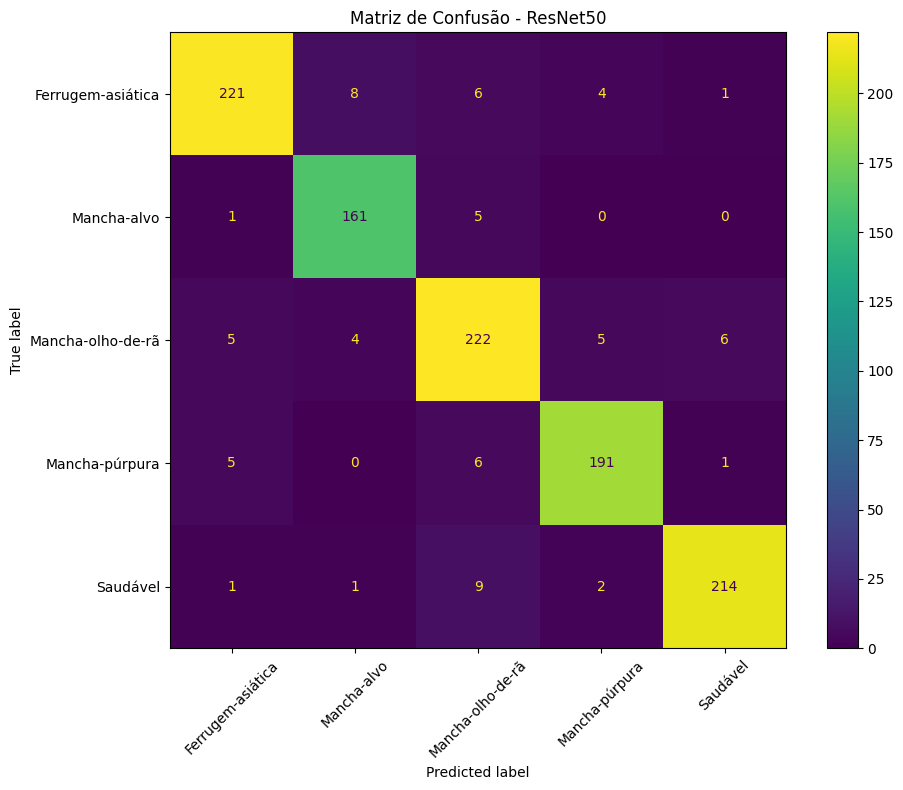


Matriz numérica:
[[221   8   6   4   1]
 [  1 161   5   0   0]
 [  5   4 222   5   6]
 [  5   0   6 191   1]
 [  1   1   9   2 214]]

Imagem salva em:
/content/drive/MyDrive/TCC/RESULTADOS/ResNet50/matriz_confusao_resnet50.png


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES_DISPLAY
)

disp.plot(
    ax=ax,
    values_format="d",
    xticks_rotation=45
)

plt.title("Matriz de Confusão - ResNet50")
plt.tight_layout()

CAMINHO_MATRIZ = RESULTADOS / "matriz_confusao_resnet50.png"

plt.savefig(
    CAMINHO_MATRIZ,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMatriz numérica:")
print(cm)

print("\nImagem salva em:")
print(CAMINHO_MATRIZ)

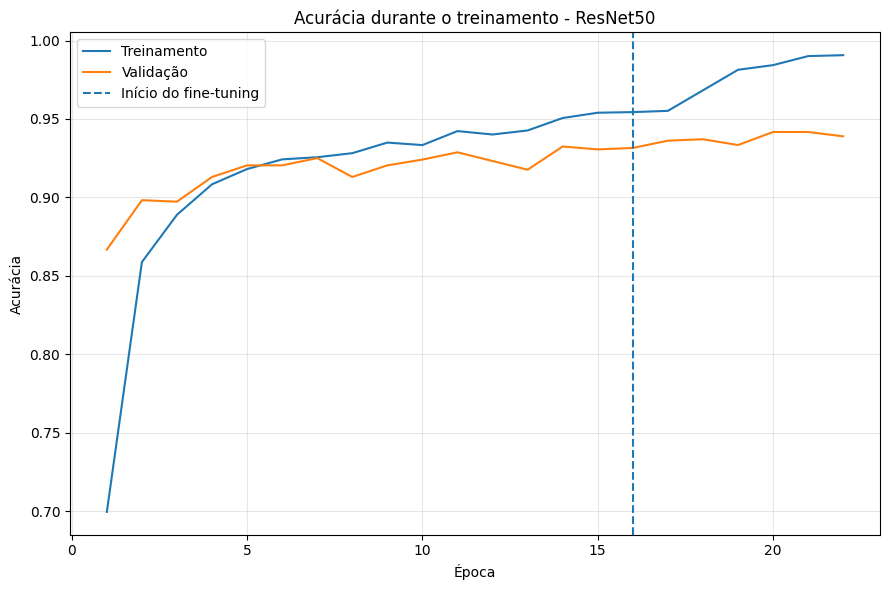

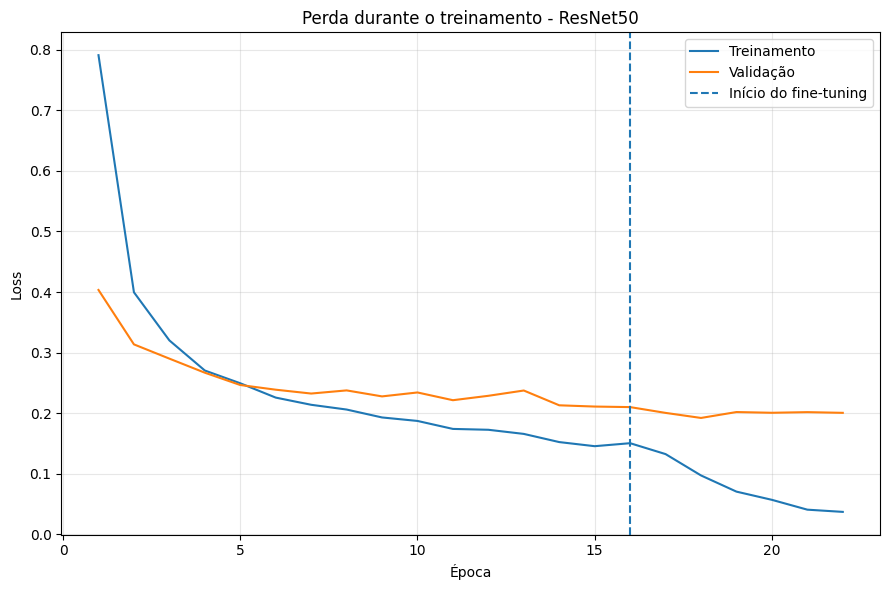

Gráfico de acurácia salvo em:
/content/drive/MyDrive/TCC/RESULTADOS/ResNet50/acuracia_resnet50.png

Gráfico de loss salvo em:
/content/drive/MyDrive/TCC/RESULTADOS/ResNet50/loss_resnet50.png


In [ ]:
import matplotlib.pyplot as plt

acc = history_fase1.history["accuracy"] + history_fase2.history["accuracy"]
val_acc = history_fase1.history["val_accuracy"] + history_fase2.history["val_accuracy"]

loss = history_fase1.history["loss"] + history_fase2.history["loss"]
val_loss = history_fase1.history["val_loss"] + history_fase2.history["val_loss"]

epochs = range(1, len(acc) + 1)
fim_fase1 = len(history_fase1.history["accuracy"])

# Acurácia
plt.figure(figsize=(9, 6))

plt.plot(epochs, acc, label="Treinamento")
plt.plot(epochs, val_acc, label="Validação")

plt.axvline(
    x=fim_fase1,
    linestyle="--",
    label="Início do fine-tuning"
)

plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.title("Acurácia durante o treinamento - ResNet50")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

CAMINHO_ACC = RESULTADOS / "acuracia_resnet50.png"

plt.savefig(
    CAMINHO_ACC,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Loss
plt.figure(figsize=(9, 6))

plt.plot(epochs, loss, label="Treinamento")
plt.plot(epochs, val_loss, label="Validação")

plt.axvline(
    x=fim_fase1,
    linestyle="--",
    label="Início do fine-tuning"
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Perda durante o treinamento - ResNet50")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

CAMINHO_LOSS = RESULTADOS / "loss_resnet50.png"

plt.savefig(
    CAMINHO_LOSS,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico de acurácia salvo em:")
print(CAMINHO_ACC)

print("\nGráfico de loss salvo em:")
print(CAMINHO_LOSS)

In [ ]:
import json

resultados_resnet50 = {
    "accuracy_teste": float(accuracy),
    "precision_macro": float(precision_macro),
    "recall_macro": float(recall_macro),
    "f1_macro": float(f1_macro),
    "loss_teste": float(test_loss),
    "historico_fase1": history_fase1.history,
    "historico_fase2": history_fase2.history
}

CAMINHO_RESULTADOS = RESULTADOS / "resultados_resnet50.json"

with open(CAMINHO_RESULTADOS, "w", encoding="utf-8") as arquivo:
    json.dump(resultados_resnet50, arquivo, indent=4)

print("JSON salvo em:")
print(CAMINHO_RESULTADOS)

JSON salvo em:
/content/drive/MyDrive/TCC/RESULTADOS/ResNet50/resultados_resnet50.json


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

relatorio = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES_DISPLAY,
    output_dict=True,
    zero_division=0
)

df_relatorio = pd.DataFrame(relatorio).transpose()

CAMINHO_RELATORIO = RESULTADOS / "relatorio_classificacao_resnet50.csv"

df_relatorio.to_csv(
    CAMINHO_RELATORIO,
    index=True,
    encoding="utf-8-sig"
)

print("CSV salvo em:")
print(CAMINHO_RELATORIO)

display(df_relatorio)

CSV salvo em:
/content/drive/MyDrive/TCC/RESULTADOS/ResNet50/relatorio_classificacao_resnet50.csv


,precision,recall,f1-score,support
Ferrugem-asiática,0.948498,0.920833,0.934461,240.000000
Mancha-alvo,0.925287,0.964072,0.944282,167.000000
Mancha-olho-de-rã,0.895161,0.917355,0.906122,242.000000
Mancha-púrpura,0.945545,0.940887,0.943210,203.000000
Saudável,0.963964,0.942731,0.953229,227.000000
accuracy,0.935125,0.935125,0.935125,0.935125
macro avg,0.935691,0.937176,0.936261,1079.000000
weighted avg,0.935641,0.935125,0.935220,1079.000000
